# AI Resume Screening (v2) — with a real trained ML classifier

The original version matched resumes to job roles purely with **keyword lookup** (and a separate, unused TF-IDF/cosine step). It called itself "AI" but no model was ever trained or evaluated.

This version adds a genuine supervised ML component:

1. **Synthetic training data** generated from the `job_roles` skill dictionary (85 roles).
2. **TF-IDF vectorization** of resume-style text.
3. A **trained classifier** (Logistic Regression) with a proper **train/test split**.
4. **Evaluation metrics** — accuracy, macro F1, confusion matrix — so the model's real performance is visible, not assumed.
5. The trained model is then used to screen an uploaded resume, alongside the original keyword extraction (kept for explainability — *why* a role was suggested).

> Note: fixed a bug from the original notebook — `job_roles` was defined twice (a 6-role version, then overwritten later by a 28-role version), so only 28 of the 60+ roles were ever actually used at screening time. This version uses the full 85-role dictionary consistently.

In [2]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import ipywidgets as widgets
from IPython.display import display, clear_output
import PyPDF2

random.seed(42)
np.random.seed(42)

## 1. Job role skill database

Same idea as the original — each role maps to a list of expected skills — but kept as a single source of truth this time (no duplicate/overwritten dict).

In [3]:
job_roles = {
    'Software Developer': ['python', 'java', 'c++', 'javascript', 'sql', 'git', 'oop', 'data structures'],
    'Python Developer': ['python', 'sql', 'django', 'flask', 'rest api', 'git', 'oop', 'postgresql'],
    'Java Developer': ['java', 'spring', 'spring boot', 'sql', 'hibernate', 'rest api', 'git'],
    'Web Developer': ['html', 'css', 'javascript', 'react', 'bootstrap', 'git'],
    'Frontend Developer': ['html', 'css', 'javascript', 'react', 'angular', 'bootstrap'],
    'Backend Developer': ['python', 'java', 'node.js', 'sql', 'api', 'django', 'flask', 'spring boot'],
    'Full Stack Developer': ['html', 'css', 'javascript', 'react', 'node.js', 'python', 'sql', 'mongodb'],
    'Software Tester': ['manual testing', 'selenium', 'testing', 'java', 'python', 'sql', 'automation testing'],
    'QA Engineer': ['quality assurance', 'testing', 'selenium', 'automation testing', 'manual testing', 'jira', 'sql'],
    'DevOps Engineer': ['linux', 'docker', 'kubernetes', 'aws', 'azure', 'jenkins', 'git', 'ci/cd'],
    'Cloud Engineer': ['aws', 'azure', 'cloud', 'docker', 'linux', 'kubernetes'],
    'Cybersecurity Analyst': ['cybersecurity', 'network security', 'linux', 'ethical hacking', 'penetration testing', 'security'],
    'Network Engineer': ['networking', 'cisco', 'routing', 'switching', 'tcp/ip', 'linux'],
    'Database Administrator': ['sql', 'mysql', 'postgresql', 'oracle', 'database', 'mongodb'],
    'Data Scientist': ['python', 'sql', 'pandas', 'numpy', 'machine learning', 'statistics', 'scikit-learn', 'data analysis', 'data visualization', 'deep learning'],
    'Data Analyst': ['python', 'sql', 'excel', 'power bi', 'tableau', 'pandas', 'statistics', 'data analysis', 'data visualization'],
    'Machine Learning Engineer': ['python', 'machine learning', 'scikit-learn', 'tensorflow', 'keras', 'deep learning', 'numpy', 'pandas', 'sql'],
    'AI Engineer': ['python', 'artificial intelligence', 'machine learning', 'deep learning', 'tensorflow', 'pytorch', 'nlp'],
    'AI/ML Engineer': ['python', 'machine learning', 'deep learning', 'tensorflow', 'pytorch', 'scikit-learn'],
    'Data Engineer': ['python', 'sql', 'spark', 'hadoop', 'etl', 'data pipeline', 'aws', 'database'],
    'Business Intelligence Analyst': ['sql', 'power bi', 'tableau', 'excel', 'data analysis', 'dashboard', 'reporting'],
    'Business Analyst': ['sql', 'excel', 'power bi', 'data analysis', 'business analysis', 'communication', 'requirements'],
    'NLP Engineer': ['python', 'nlp', 'natural language processing', 'machine learning', 'deep learning', 'transformers'],
    'Computer Vision Engineer': ['python', 'computer vision', 'opencv', 'deep learning', 'tensorflow', 'pytorch'],
    'Accountant': ['accounting', 'tally', 'excel', 'bookkeeping', 'taxation', 'financial accounting'],
    'Junior Accountant': ['accounting', 'tally', 'excel', 'bookkeeping', 'invoice'],
    'Finance Executive': ['finance', 'accounting', 'excel', 'financial analysis', 'budgeting'],
    'Financial Analyst': ['finance', 'financial analysis', 'excel', 'accounting', 'financial modeling', 'valuation'],
    'Investment Analyst': ['finance', 'investment', 'financial analysis', 'valuation', 'excel', 'market research'],
    'Banking Executive': ['banking', 'finance', 'accounting', 'customer service', 'excel'],
    'Tax Associate': ['taxation', 'gst', 'income tax', 'accounting', 'tally', 'finance'],
    'HR Executive': ['human resources', 'recruitment', 'employee relations', 'payroll', 'communication', 'hr'],
    'HR Recruiter': ['recruitment', 'talent acquisition', 'sourcing', 'interview', 'communication', 'linkedin'],
    'Talent Acquisition Specialist': ['talent acquisition', 'recruitment', 'sourcing', 'interview', 'hr'],
    'HR Coordinator': ['human resources', 'hr', 'communication', 'employee relations', 'documentation'],
    'Digital Marketing Executive': ['digital marketing', 'seo', 'social media marketing', 'google ads', 'content marketing'],
    'SEO Analyst': ['seo', 'keyword research', 'google analytics', 'digital marketing', 'content'],
    'Social Media Executive': ['social media', 'content creation', 'instagram', 'facebook', 'digital marketing'],
    'Marketing Executive': ['marketing', 'sales', 'communication', 'market research', 'customer relationship'],
    'Sales Executive': ['sales', 'communication', 'customer service', 'lead generation', 'negotiation'],
    'Business Development Executive': ['business development', 'sales', 'lead generation', 'communication', 'negotiation', 'client relationship'],
    'Customer Relationship Executive': ['customer service', 'communication', 'customer relationship', 'sales', 'crm'],
    'Mechanical Engineer': ['mechanical engineering', 'autocad', 'solidworks', 'thermodynamics', 'manufacturing', 'cad'],
    'Production Engineer': ['production', 'manufacturing', 'mechanical engineering', 'quality control', 'cad'],
    'Maintenance Engineer': ['maintenance', 'mechanical engineering', 'machinery', 'troubleshooting', 'manufacturing'],
    'Civil Engineer': ['civil engineering', 'autocad', 'construction', 'structural engineering', 'surveying', 'estimation'],
    'Site Engineer': ['civil engineering', 'construction', 'site management', 'autocad', 'project management'],
    'Structural Engineer': ['civil engineering', 'structural engineering', 'staad pro', 'autocad', 'structural analysis'],
    'Electrical Engineer': ['electrical engineering', 'electrical systems', 'circuit', 'power systems', 'autocad'],
    'Electronics Engineer': ['electronics', 'embedded systems', 'microcontroller', 'pcb', 'circuit', 'arduino'],
    'Embedded Systems Engineer': ['embedded systems', 'c', 'c++', 'microcontroller', 'arduino', 'raspberry pi'],
    'Automobile Engineer': ['automobile engineering', 'automotive', 'vehicle', 'mechanical engineering', 'cad'],
    'Pharmacy Assistant': ['pharmacy', 'pharmaceutical', 'medicine', 'drug', 'pharmacology'],
    'Medical Coding Associate': ['medical coding', 'medical terminology', 'healthcare', 'icd', 'cpt'],
    'Medical Transcriptionist': ['medical transcription', 'medical terminology', 'healthcare', 'typing'],
    'Healthcare Administrator': ['healthcare', 'hospital administration', 'management', 'communication', 'documentation'],
    'Research Assistant': ['research', 'statistics', 'data analysis', 'research methodology', 'documentation'],
    'Laboratory Assistant': ['laboratory', 'laboratory techniques', 'research', 'documentation'],
    'Research Analyst': ['research', 'data analysis', 'statistics', 'excel', 'report writing'],
    'Graphic Designer': ['graphic design', 'photoshop', 'illustrator', 'canva', 'adobe', 'design'],
    'UI/UX Designer': ['ui design', 'ux design', 'figma', 'wireframing', 'prototyping', 'user research'],
    'Video Editor': ['video editing', 'premiere pro', 'after effects', 'davinci resolve', 'video production'],
    'Content Writer': ['content writing', 'copywriting', 'creative writing', 'seo', 'content creation'],
    'Teacher': ['teaching', 'education', 'lesson planning', 'communication', 'classroom management'],
    'Teaching Assistant': ['teaching', 'education', 'communication', 'academic'],
    'Academic Coordinator': ['education', 'coordination', 'communication', 'student management', 'administration'],
    'Operations Executive': ['operations', 'management', 'communication', 'excel', 'process management'],
    'Process Associate': ['data entry', 'process management', 'documentation', 'quality', 'communication', 'excel'],
    'Quality Analyst': ['quality assurance', 'quality control', 'testing', 'process improvement', 'documentation'],
    'Administrative Assistant': ['administration', 'documentation', 'communication', 'ms office', 'excel', 'data entry'],
    'Office Administrator': ['office administration', 'documentation', 'communication', 'excel', 'ms office'],
    'Logistics Executive': ['logistics', 'supply chain', 'inventory', 'warehouse', 'transportation', 'excel'],
    'Supply Chain Analyst': ['supply chain', 'inventory', 'data analysis', 'excel', 'logistics', 'forecasting'],
    'Warehouse Executive': ['warehouse', 'inventory', 'logistics', 'stock management', 'excel'],
    'Hotel Management Executive': ['hotel management', 'hospitality', 'customer service', 'front office', 'communication'],
    'Front Office Executive': ['front office', 'hospitality', 'customer service', 'communication', 'hotel'],
    'Guest Relations Executive': ['guest relations', 'hospitality', 'customer service', 'communication'],
    'Travel Consultant': ['travel', 'tourism', 'customer service', 'communication', 'travel planning'],
    'Tourism Executive': ['tourism', 'travel', 'hospitality', 'communication', 'customer service'],
    'Legal Assistant': ['law', 'legal research', 'documentation', 'legal', 'communication'],
    'Legal Associate': ['law', 'legal research', 'legal drafting', 'documentation', 'legal'],
    'Customer Support Executive': ['customer service', 'communication', 'problem solving', 'customer support'],
    'Data Entry Operator': ['data entry', 'typing', 'excel', 'ms office', 'documentation'],
    'Back Office Executive': ['back office', 'data entry', 'excel', 'documentation', 'communication'],
    'Process Executive': ['process management', 'data entry', 'documentation', 'communication', 'excel'],
}

## 2. Build a synthetic training set

Real labelled resume data isn't available here, so we generate synthetic "resume snippets" per role by sampling subsets of that role's skills into template sentences. This is a genuine (if simplified) supervised learning setup: different runs, different skill subsets, different sentence templates — so the model has to learn from word patterns, not memorize one fixed sentence.

This is also an honest limitation to flag in an interview: **synthetic data is a stand-in for real labelled resumes**. With real data (e.g. a public resume-role dataset from Kaggle) this pipeline would be more trustworthy.

In [4]:
TEMPLATES = [
    "Experienced professional skilled in {skills}.",
    "I have hands-on experience with {skills} and related tools.",
    "Proficient in {skills}, with practical project experience.",
    "Strong background in {skills} gained through academic and internship projects.",
    "Looking for a role that makes use of my skills in {skills}.",
    "My core competencies include {skills}.",
    "Worked on multiple projects involving {skills}.",
    "Seeking a position that utilises my knowledge of {skills}.",
]

def generate_samples(skills, n_samples=15):
    samples = []
    for _ in range(n_samples):
        k = random.randint(max(2, len(skills) - 3), len(skills))
        chosen = random.sample(skills, min(k, len(skills)))
        random.shuffle(chosen)
        template = random.choice(TEMPLATES)
        samples.append(template.format(skills=", ".join(chosen)))
    return samples

texts, labels = [], []

for role, skills in job_roles.items():
    for sample in generate_samples(skills, n_samples=15):
        texts.append(sample)
        labels.append(role)

train_df = pd.DataFrame({"text": texts, "role": labels})
print("Total synthetic samples:", len(train_df))
print("Roles:", train_df['role'].nunique())
train_df.sample(5, random_state=1)

Total synthetic samples: 1275
Roles: 85


,text,role
920,Experienced professional skilled in video edit...,Video Editor
817,"Worked on multiple projects involving typing, ...",Medical Transcriptionist
443,"Strong background in customer service, excel g...",Banking Executive
701,Worked on multiple projects involving civil en...,Site Engineer
108,I have hands-on experience with automation tes...,Software Tester


## 3. Vectorize + train/test split

In [5]:
def preprocess_text(text):
    text = text.lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

train_df["clean_text"] = train_df["text"].apply(preprocess_text)

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1)
X = vectorizer.fit_transform(train_df["clean_text"])
y = train_df["role"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Train samples:", X_train.shape[0])
print("Test samples :", X_test.shape[0])
print("Features (TF-IDF terms):", X_train.shape[1])

Train samples: 956
Test samples : 319
Features (TF-IDF terms): 2629


## 4. Train the classifier

In [6]:
clf = LogisticRegression(max_iter=2000, class_weight="balanced")
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)

print("Test accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1 score:", round(f1_score(y_test, y_pred, average="macro"), 4))

Test accuracy : 0.9028
Macro F1 score: 0.9016


## 5. Evaluate properly

With 85 classes a full confusion matrix isn't readable, so we look at:
- the full classification report (precision/recall/F1 per role)
- a confusion matrix zoomed into the roles the model confuses most often

In [7]:
print(classification_report(y_test, y_pred, zero_division=0))

                                 precision    recall  f1-score   support

                    AI Engineer       1.00      1.00      1.00         3
                 AI/ML Engineer       1.00      1.00      1.00         4
           Academic Coordinator       1.00      1.00      1.00         4
                     Accountant       1.00      1.00      1.00         4
       Administrative Assistant       1.00      0.67      0.80         3
            Automobile Engineer       1.00      1.00      1.00         4
          Back Office Executive       1.00      0.75      0.86         4
              Backend Developer       1.00      1.00      1.00         4
              Banking Executive       1.00      0.75      0.86         4
               Business Analyst       1.00      1.00      1.00         4
 Business Development Executive       1.00      1.00      1.00         3
  Business Intelligence Analyst       1.00      1.00      1.00         3
                 Civil Engineer       1.00      1.

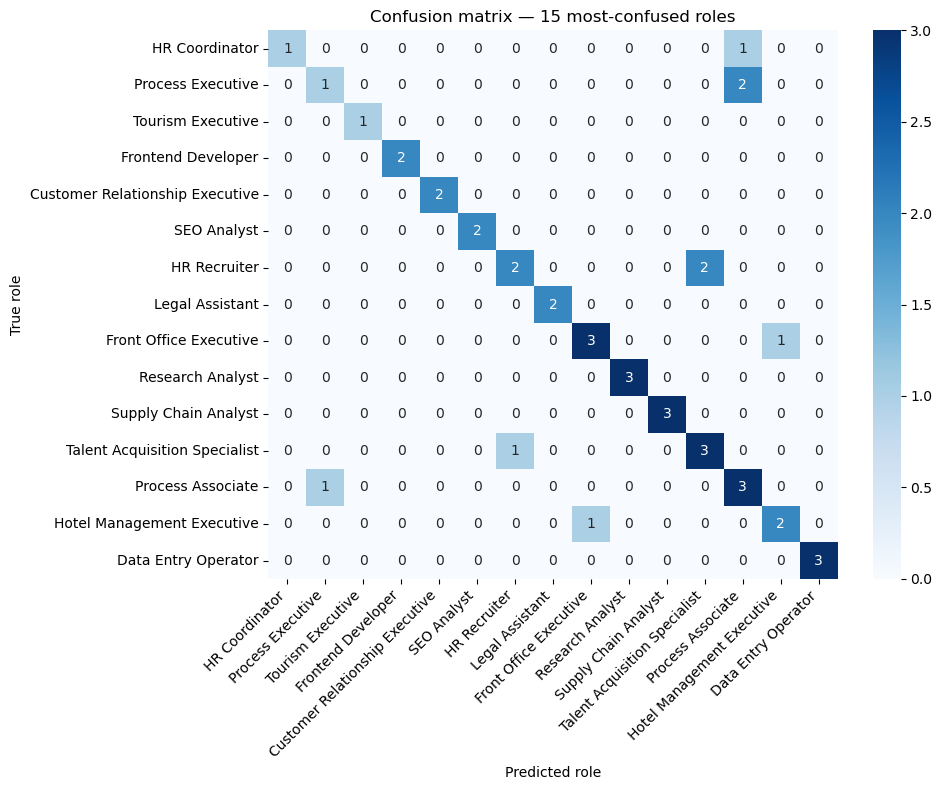

In [8]:
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
cm_df = pd.DataFrame(cm, index=clf.classes_, columns=clf.classes_)

# Find the roles most often confused with something else (off-diagonal errors)
off_diag_errors = (cm_df.sum(axis=1) - pd.Series(np.diag(cm_df), index=cm_df.index))
worst_roles = off_diag_errors.sort_values(ascending=False).head(15).index

plt.figure(figsize=(10, 8))
sns.heatmap(cm_df.loc[worst_roles, worst_roles], annot=True, fmt="d", cmap="Blues")
plt.title("Confusion matrix — 15 most-confused roles")
plt.ylabel("True role")
plt.xlabel("Predicted role")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 6. Resume screening — keyword extraction (kept for explainability)

The ML model gives a *ranked prediction* of likely roles. Keyword matching is kept alongside it to explain *why* — which skills were actually found in the resume, and which ones are missing for the top-predicted role. This hybrid (ML ranking + rule-based explanation) is more honest than either approach alone.

In [9]:
all_skills = sorted(set(skill for skills in job_roles.values() for skill in skills))

def extract_skills(resume_text):
    text_lower = resume_text.lower()
    return sorted([s for s in all_skills if s in text_lower])

def match_report(resume_text, top_role):
    found = extract_skills(resume_text)
    required = job_roles[top_role]
    matched = [s for s in required if s in found]
    missing = [s for s in required if s not in found]
    return found, matched, missing

## 7. Upload + screen a resume

In [10]:
upload = widgets.FileUpload(accept=".pdf", multiple=False, description="📤 Upload Resume")
display(upload)

screen_button = widgets.Button(description="🔍 Screen Resume", button_style="primary")
display(screen_button)

output = widgets.Output()
display(output)


def process_resume(button):
    with output:
        clear_output()

        if not upload.value:
            print("❌ Please upload a PDF resume first.")
            return

        try:
            value = upload.value
            file_info = list(value.values())[0] if isinstance(value, dict) else value[0]
            file_name = file_info["name"]
            file_content = file_info["content"]

            from io import BytesIO
            reader = PyPDF2.PdfReader(BytesIO(file_content))
            resume_text = ""
            for page in reader.pages:
                page_text = page.extract_text()
                if page_text:
                    resume_text += page_text + "\n"
            resume_text = resume_text.strip()

            if not resume_text:
                print("❌ No readable text found in this PDF (may be scanned/image-based).")
                return

            clean = preprocess_text(resume_text)
            vec = vectorizer.transform([clean])

            proba = clf.predict_proba(vec)[0]
            ranking = sorted(zip(clf.classes_, proba), key=lambda x: x[1], reverse=True)
            top_role, top_score = ranking[0]

            found, matched, missing = match_report(resume_text, top_role)

            print("=" * 75)
            print("                AI RESUME SCREENING (ML-based)")
            print("=" * 75)
            print("\nFile:", file_name)

            print("\n🏆 MODEL PREDICTION (top 5 roles, by trained classifier)")
            print("-" * 75)
            for role, score in ranking[:5]:
                print(f"{role:<35}{score*100:>6.2f}%")

            print("\n✅ SKILLS FOUND IN RESUME")
            print("-" * 75)
            print(", ".join(found) if found else "No matching skills detected.")

            print(f"\n📋 WHY '{top_role}'? — matched vs missing skills")
            print("-" * 75)
            print("Matched:", ", ".join(matched) if matched else "none")
            print("Missing:", ", ".join(missing) if missing else "none — strong match")

            plt.figure(figsize=(8, 5))
            roles_top, scores_top = zip(*ranking[:5])
            plt.barh(roles_top[::-1], [s * 100 for s in scores_top][::-1])
            plt.xlabel("Model confidence (%)")
            plt.title("Top predicted roles")
            plt.tight_layout()
            plt.show()

        except Exception as e:
            print("❌ Error:", str(e))


screen_button.on_click(process_resume)

FileUpload(value=(), accept='.pdf', description='📤 Upload Resume')

Button(button_style='primary', description='🔍 Screen Resume', style=ButtonStyle())

Output()